# Where does the pricing policy fail to adapt?

The hotel starts with **330 days and 10 rooms** for one arrival date. At most one room sells each day; the rest carry forward. Performance means revenue across the entire selling period.

A sale today gives up a possible sale later. Even though sale probability at a given price stays constant in this simulator, the value of retaining a room changes with time and inventory. The best policy sometimes discounts and sometimes charges more for scarce rooms. The original neural policy mostly charges 90.

This notebook maps that limited adaptation, inspects several contrasting situations, and evaluates the first attempt to improve the data.

**Words used in this notebook**

- **Policy:** a rule for choosing a price from days and rooms remaining.
- **Q score:** the model's estimate of revenue from a price, including future sales.
- **CQL:** Conservative Q-Learning, the method that fits this neural model from saved decisions and outcomes. It discourages overly optimistic scores relative to recorded actions.
- **Margin:** one Q score minus another. A negative `Q(55) − Q(90)` favors 90 over 55.
- **Planner:** a separate method that estimates sale probabilities and calculates a pricing rule using known inventory dynamics.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'hotel_pricing').is_dir() and (p / 'configs/environment.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the hotel-pricing repository.')
sys.path.insert(0, str(ROOT))
from scripts.policy_improvement.presentation import (MODEL_NAMES, LEGACY_NAMES, EPISODE_NAMES, REVISED_DEFINITION,
    case_label, case_table, regional_table, policy_maps)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)
def required(path):
    if not path.is_file():
        raise FileNotFoundError(f'Required saved evidence is missing: {path}. See README.md.')
    return path
def figure(name):
    path = OUT / 'figures' / f'{name}.png'
    if path.is_file(): display(Image(filename=str(path), width=1000))
    else: print(f'Optional display image unavailable: {path.name}; numerical evidence remains required.')

PLAN=json.loads(required(ROOT/'configs/policy_improvement/coverage.json').read_text())
OUT=ROOT/PLAN['output']
summary=json.loads(required(OUT/'summary.json').read_text())
cases=json.loads(required(OUT/'audit/historical_0_cases.json').read_text())
one_day=next(c for c in cases if c['state']==[1,1])


Matplotlib is building the font cache; this may take a moment.


## 1. Does the policy adapt across time and inventory?

A policy map shows the selected price at every reachable combination of days and rooms remaining. The original saved model (seed 0) below began the audit. It is distinct from the fresh baseline comparisons used in the next notebook.

**Takeaway: the original saved model mostly chooses 90; the optimum responds to both selling pressure and scarcity.**

Days count down from left to right. A marks (200 days, 10 rooms), B marks (200, 2), C marks (50, 10), and D marks (1, 1). The dashed line marks the final 30 days. Blank states are unreachable.


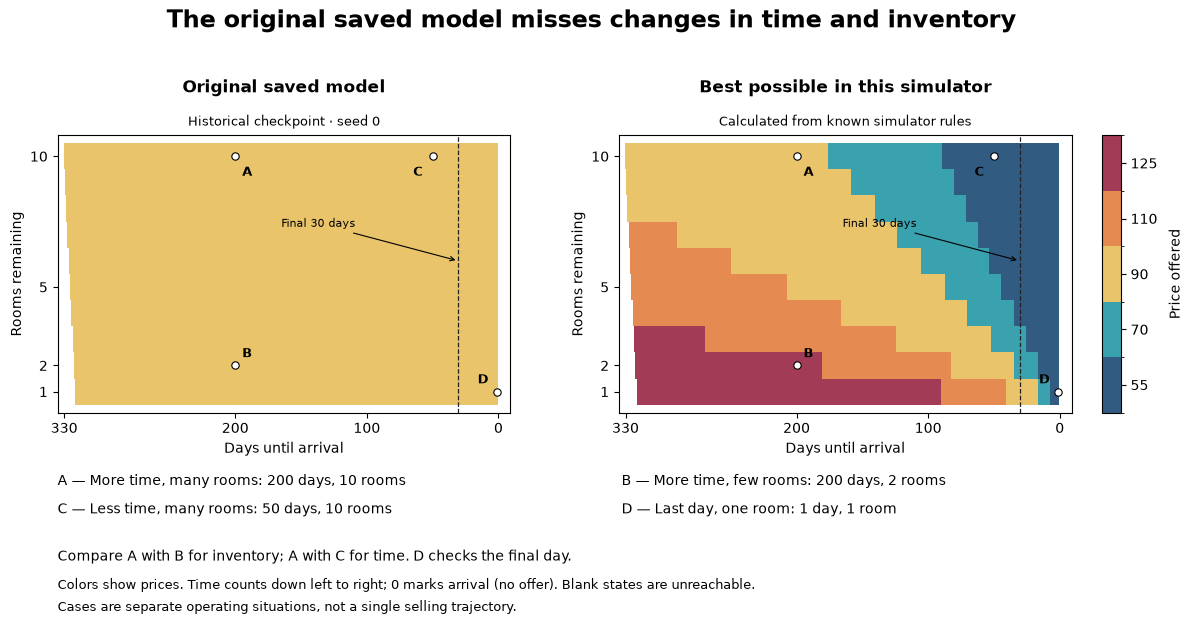

In [2]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from hotel_pricing.environment import load_config
from hotel_pricing.xai_audit import reachable,load_model,model_values
from hotel_pricing.evaluation import solve
CONFIG=load_config(ROOT/PLAN['environment'])
model,_=load_model(ROOT/PLAN['original_models']/'cql_seed_0.pt',CONFIG)
policy=model_values(model,CONFIG).argmax(2)
mask=reachable(CONFIG)
fig=policy_maps([
 (MODEL_NAMES['historical'],'Historical checkpoint · seed 0',policy),
 ('Best possible in this simulator','Calculated from known simulator rules',solve(CONFIG)[1])],
 mask,'The original saved model misses changes in time and inventory')
plt.show()

## 2. When is 90 appropriate, and when should the price change?

Hold time fixed at 200 days. The optimum charges 90 with 10 rooms but 125 with only two. A higher price preserves scarce inventory for later opportunities. With 50 days and 10 rooms, the optimum discounts to 55.

These fixed cases illustrate different situations; they are not a single trajectory or a representative sample of states. **Charging 90 is not inherently wrong. Failing to adapt is the issue.**


In [3]:
case_lookup={tuple(c['state']):c for c in cases}
selected_states=[(200,10),(200,2),(50,10),(1,1)]
display(pd.DataFrame([{'Situation':case_label(t,r),
 'Original saved model (seed 0)':case_lookup[t,r]['price'],
 'Best possible in this simulator':CONFIG.prices[int(np.argmax(case_lookup[t,r]['q_star']))],
 'Original offers here':sum(case_lookup[t,r]['support'])} for t,r in selected_states]))

,Situation,Original saved model (seed 0),Best possible in this simulator,Original offers here
0,"A — More time, many rooms: 200 days, 10 rooms",90.0,90,2
1,"B — More time, few rooms: 200 days, 2 rooms",90.0,125,173
2,"C — Less time, many rooms: 50 days, 10 rooms",90.0,55,0
3,"D — Last day, one room: 1 day, 1 room",90.0,55,37


## 3. What do the scores favor, and what evidence supports them?

The model chooses the largest of five Q scores. A **Shapley attribution** splits a pairwise margin into contributions from time and inventory relative to reference situations:

`reference margin + time contribution + inventory contribution = current margin`

Use `Q(55) − Q(90)` for discounting and `Q(125) − Q(90)` for scarcity. A negative margin favors 90 over that alternative. The full decision still compares all five prices.

The table connects two contrasts with the original records at those states. Scores use revenue divided by 90; they describe model preferences, not verified revenue. Flat decisions do not imply that the scores ignore inventory.


In [4]:
preferences=[]
for state,alternative in [((50,10),'55'),((200,2),'125')]:
    c=case_lookup[state];attribution=c['attributions'][alternative]
    preferences.append({'days':state[0],'rooms':state[1],'contrast':f'{alternative}-90',
      'selected_price':c['price'],'reference_margin':attribution['base'],
      'time_contribution':attribution['days'],'inventory_contribution':attribution['rooms'],
      'margin':attribution['margin'],'offers_by_price':dict(zip(CONFIG.prices,c['support']))})
display(pd.DataFrame(preferences))

,days,rooms,contrast,selected_price,reference_margin,time_contribution,inventory_contribution,margin,offers_by_price
0,50,10,55-90,90.0,-0.242065,0.007094,0.105584,-0.129387,"{55: 0, 70: 0, 90: 0, 110: 0, 125: 0}"
1,200,2,125-90,90.0,-0.127830,0.000296,0.007852,-0.119682,"{55: 19, 70: 13, 90: 77, 110: 38, 125: 26}"


### What does the final day isolate?

With one day and one room, no future sale is possible. This is a simple diagnostic for separating the network's ranking from the simulator's immediate-revenue calculation.

**Takeaway: the original saved model favors 90, while 55 earns more in expectation.** The network scores are divided by 90; the simulator column is in revenue units. Compare rankings within each column.


In [5]:
display(pd.DataFrame({'price':[55,70,90,110,125],
    'model_Q_score_scaled':one_day['q_model'],
    'simulator_expected_revenue':one_day['q_star'],
    'recorded_offers_here':one_day['support']}))
print('Model choice:',one_day['price'])

,price,model_Q_score_scaled,simulator_expected_revenue,recorded_offers_here
0,55,1.302762,8.341662,3
1,70,1.428961,5.885085,3
2,90,1.596516,3.272727,21
3,110,1.537253,1.680434,4
4,125,1.493570,0.987756,6


Model choice: 90.0


### Can sparse local data still contain useful information overall?

At the final-day case, there are only 37 recorded offers. Price 55 appears three times, with no sales. Across the original dataset, however, it has 32,492 offers and 4,931 sales.

A separate planner pools offers by price and uses known inventory rules. It nearly reaches the optimum without new collection. This is a preview of Notebook 2: useful information exists, but the neural learner may not use it effectively in each situation.


In [6]:
planner=json.loads(required(ROOT/'outputs/policy_improvement/training/diagnostics/learned_demand.json').read_text())
display(pd.DataFrame([{'policy':MODEL_NAMES['historical'],'episode_revenue':summary['historical_audit'][0]['exact_revenue']},
 {'policy':MODEL_NAMES['planner'],'episode_revenue':planner['exact_revenue']},
 {'policy':MODEL_NAMES['optimal'],'episode_revenue':planner['exact_revenue']+planner['oracle_gap']}]))

,policy,episode_revenue
0,Original saved model,851.003070
1,Planner fitted to the original data,888.373761
2,Best possible in this simulator,888.410341


## 4. Did adding more selling periods help?

The experiment compares the original data with two additions of 400 complete selling periods. One uses the usual price mix. The other tries all prices more evenly in the last 30 days.

Only 22 added periods in each group actually reach that late window. Many sell out earlier. This is why collecting complete periods may still provide little evidence for the late-window region.

**Takeaway: these episode additions do not establish an improvement; the important situations remain sparsely observed.**


The collection labels distinguish **Original data**, **+400 usual-price periods**, and **+400 late-exploration periods**. These additions are different from the later baseline comparisons, which train on the original data alone.

,Collection,Training seed,Expected revenue per selling period,Gain over fixed price 90
0,Original data,0,851.003070,0.000000
1,Original data,1,851.003070,0.000000
2,Original data,2,851.082355,0.079285
3,+400 usual-price periods,0,851.003070,0.000000
4,+400 usual-price periods,1,851.003070,0.000000
5,+400 usual-price periods,2,851.003070,0.000000
6,+400 late-exploration periods,0,851.003070,0.000000
7,+400 late-exploration periods,1,851.003070,0.000000
8,+400 late-exploration periods,2,851.003070,0.000000


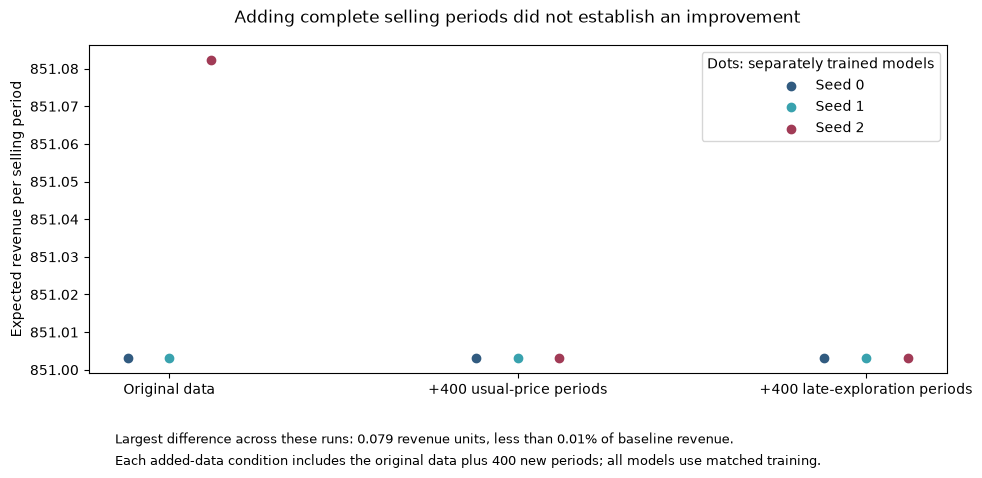

In [7]:
episode_results=pd.DataFrame(summary['metrics'])
episode_results['Collection']=episode_results.arm.map(EPISODE_NAMES)
display(episode_results[['Collection','seed','exact_revenue','minus_fixed90']].rename(columns={
 'seed':'Training seed','exact_revenue':'Expected revenue per selling period','minus_fixed90':'Gain over fixed price 90'}))
fig,ax=plt.subplots(figsize=(10,4.8))
for x,arm in enumerate(EPISODE_NAMES):
    part=episode_results[episode_results.arm==arm].sort_values('seed')
    for shift,row in zip([-.12,0,.12],part.itertuples()):
        ax.scatter(x+shift,row.exact_revenue,label=f'Seed {row.seed}' if x==0 else None,
                   color=['#315b80','#39a2ae','#a13b56'][row.seed])
ax.set_xticks(range(3),list(EPISODE_NAMES.values()),fontsize=10)
ax.set_ylabel('Expected revenue per selling period')
ax.set_title('Adding complete selling periods did not establish an improvement',pad=16)
ax.legend(title='Dots: separately trained models')
spread=episode_results.exact_revenue.max()-episode_results.exact_revenue.min()
assert spread/episode_results.exact_revenue.min()*100 < .01
fig.text(.12,.065,f'Largest difference across these runs: {spread:.3f} revenue units, less than 0.01% of baseline revenue.',fontsize=9)
fig.text(.12,.02,'Each added-data condition includes the original data plus 400 new periods; all models use matched training.',fontsize=9)
fig.tight_layout(rect=[0,.13,1,1]);plt.show()

## 5. Which hypotheses should be tested next?

- **Learning mechanics:** do input scaling, reward units, and episode endings work as intended?
- **Use of existing data:** can longer training or more late-window replay help?
- **Coverage:** can targeted new outcomes improve decisions where complete episodes provide little exposure?
- **Structure:** how much can a planner achieve by pooling the original records?

[Which changes improve the full pricing policy?](02_learning_improvement.ipynb) tests these questions. Its acceptance criterion is full-period revenue; local cases show where improvement occurs and where it fails.


## What does this not show?

- These results do not establish real-hotel performance; the demand law is assumed.
- In Notebook 2’s confirmation study, three training seeds share one newly collected balanced dataset. They are not three independent collections.
- A better overall policy can still make poor local decisions or have inaccurate Q scores.
- Explanations guided the questions, but no experiment measured XAI versus no XAI.
- The planner's strong result depends on price-only, stationary demand.


## Appendix: How can the evidence be checked?

The tables below preserve all six cases, reference sensitivity, provenance, and the optional explorer.

**Common-reference regret** means revenue lost from weak decisions, averaged using the same fixed-90 visiting pattern for every policy. It helps locate errors. It is different from each policy's actual total revenue gap.

Historical models and fresh original-data comparison models have separate identities. Historical source hashes differ from current source, so the fresh arm provides the matched training reference.


In [8]:
display(pd.DataFrame(json.loads(required(OUT/'inventory.json').read_text()))[['role','path','exists']])
display(pd.DataFrame(summary['historical_audit']))
display(pd.read_json(required(ROOT/'docs/policy_improvement/evidence/reference_sensitivity.json')))
display(pd.DataFrame([{'state':c['state'],'selected_price':c['price'],'counterfactual':c['counterfactual']} for c in cases]))
display(pd.DataFrame(summary['paired']))

,role,path,exists
0,environment,configs/environment.json,True
1,dataset manifest,data/simulated/baseline/manifest.json,True
2,source metadata,data/source.json,True
3,raw bookings,data/raw/h2.csv,True
4,original results,outputs/baseline/cql/results.json,True
5,original policies,outputs/baseline/cql/policies.npz,True
6,comparison,outputs/baseline/comparison/comparison.json,True
7,checkpoint,outputs/baseline/cql/cql_seed_0.pt,True
8,checkpoint,outputs/baseline/cql/cql_seed_1.pt,True
9,checkpoint,outputs/baseline/cql/cql_seed_2.pt,True


,model,exact_revenue,gap,gap_percent,minus_fixed90,target_gap,scarcity_gap,support_at_most4_gap,common_target_regret,common_total_regret,max_shapley_reconstruction_error,prices_on_reachable_states,case_prices
0,historical_0,851.003070,37.407271,4.210585,0.000000,17.434874,18.120696,21.078516,17.434874,37.407271,0.0,"{'55': 0, '70': 0, '90': 3255, '110': 0, '125': 0}","[90.0, 90.0, 90.0, 90.0, 90.0, 90.0]"
1,historical_1,851.003070,37.407271,4.210585,0.000000,17.434874,18.120696,21.078516,17.434874,37.407271,0.0,"{'55': 0, '70': 0, '90': 3255, '110': 0, '125': 0}","[90.0, 90.0, 90.0, 90.0, 90.0, 90.0]"
2,historical_2,851.082355,37.327986,4.201660,0.079285,17.370489,18.121003,20.999186,17.344643,37.300195,0.0,"{'55': 0, '70': 198, '90': 3057, '110': 0, '125': 0}","[90.0, 90.0, 70.0, 90.0, 90.0, 90.0]"


,state,contrast,days_change,rooms_change,days_sign_changed,rooms_sign_changed
0,"[200, 2]",55,0.001945,-0.010958,False,False
1,"[200, 2]",125,0.000658,0.001733,False,False
2,"[200, 10]",55,0.000719,-0.009732,False,False
3,"[200, 10]",125,0.000365,0.002025,True,False
4,"[50, 10]",55,-0.000197,-0.008816,False,False
5,"[50, 10]",125,0.000475,0.001915,False,False
6,"[1, 1]",55,0.000679,-0.009692,False,False
7,"[1, 1]",125,0.000716,0.001674,False,False
8,"[128, 1]",55,0.001623,-0.010636,False,False
9,"[128, 1]",125,0.000726,0.001665,False,False


,state,selected_price,counterfactual
0,"[200, 2]",90.0,None
1,"[200, 10]",90.0,None
2,"[50, 10]",90.0,None
3,"[1, 1]",90.0,None
4,"[128, 1]",90.0,None
5,"[321, 10]",90.0,None


,comparison,seed,exact_difference,mean,ci95_half_width
0,targeted_minus_ordinary,0,0.000000,0.0,0.0
1,ordinary_minus_original,0,0.000000,0.0,0.0
2,targeted_minus_original,0,0.000000,0.0,0.0
3,targeted_minus_ordinary,1,0.000000,0.0,0.0
4,ordinary_minus_original,1,0.000000,0.0,0.0
5,targeted_minus_original,1,0.000000,0.0,0.0
6,targeted_minus_ordinary,2,0.000000,0.0,0.0
7,ordinary_minus_original,2,-0.079285,0.0,0.0
8,targeted_minus_original,2,-0.079285,0.0,0.0


### Which alternative situation changes the price?

A counterfactual state comparison searches for a nearby possible situation where the full five-price choice changes. No solution is a valid result for a constant policy. Distance is `abs(change in days)/330 + abs(change in rooms)/10`, with fixed tie-breaking.

These are comparisons of operating conditions, not advice to change the clock or remove rooms. Simulator action values below state whether later decisions follow the optimum or the named learned policy.

The optional explorer reads frozen models. Changing its arguments does not train a new model.


The demonstration uses 200 days and two rooms. Here the simulator values differ depending on whether later decisions follow the optimum or the named learned policy. Both include future revenue.

In [9]:
from hotel_pricing.environment import load_config
from hotel_pricing.xai_audit import reachable, load_model, model_values, simulator_values, counterfactual
from hotel_pricing.offline_data import load_dataset
from hotel_pricing.policy_gap import explain_gap
CONFIG = load_config(ROOT/PLAN['environment'])
def explore(days, rooms, arm='historical', seed=0):
    if arm not in ['historical','original','ordinary','targeted'] or seed not in [0,1,2]:
        raise ValueError('Choose a documented arm and seed')
    if not (isinstance(days,int) and isinstance(rooms,int) and 1<=days<=330 and 1<=rooms<=10 and reachable(CONFIG)[days,rooms]):
        raise ValueError('Choose a reachable nonterminal integer state')
    path = ROOT/PLAN['original_models']/f'cql_seed_{seed}.pt' if arm=='historical' else OUT/'models'/arm/f'cql_seed_{seed}.pt'
    model,_=load_model(path,CONFIG)
    q=model_values(model,CONFIG); policy=q.argmax(axis=2)
    dataset=ROOT/(PLAN['original_data'] if arm in ['historical','original'] else PLAN['data_output']+'/'+arm)
    support=explain_gap(CONFIG,policy,load_dataset(dataset,'train'))['counts']
    qstar,_=simulator_values(CONFIG); qpolicy,_=simulator_values(CONFIG,policy)
    display(Markdown(f'**Selected price: {CONFIG.prices[policy[days,rooms]]}.** Operating-condition comparison: {counterfactual(policy,[days,rooms],CONFIG)}'))
    return pd.DataFrame({'price':CONFIG.prices,'q_model_scaled':q[days,rooms],
        'q_star_revenue':qstar[days,rooms],'q_policy_revenue':qpolicy[days,rooms],'support':support[days,rooms]})
display(explore(200,2))

**Selected price: 90.** Operating-condition comparison: None

,price,q_model_scaled,q_star_revenue,q_policy_revenue,support
0,55,4.620012,202.086806,174.226324,19
1,70,4.765069,206.143593,177.820635,13
2,90,4.943216,208.128483,179.479101,77
3,110,4.869446,208.568133,179.774475,38
4,125,4.823534,208.586075,179.741960,26


The [report appendix](../../docs/policy_improvement/report.md#appendix-how-were-the-results-checked) defines the reference game and feasibility rules. The [repository README](../../README.md#saved-evidence-supports-reproduction) records reproduction commands.